# Selected simulation figures

This focused notebook generates only the requested figures:

1. Enumeration coverage for the default, attacker-fraction, and churn-rate experiments.
2. Blocking-mode unsuccessful-request rate for attacker fraction, churn rate, and connection duration.
3. Blocking-mode total client retries with daily percentile bands for attacker fraction, churn rate, and connection duration.
4. Default-scenario comparisons for normal, 0.1×, and 0.5× standalone-proxy churn.

Every non-default plot includes the corresponding default curve for comparison. Figures are saved as PDFs under `figures/selected_simulation_figures/`.

In [1]:
from pathlib import Path
import importlib
import sys

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display


def find_repository_root(start=Path.cwd()):
    candidates = [start.resolve(), *start.resolve().parents]
    for candidate in candidates:
        helper = candidate / 'simulation_variation_analysis.py'
        if (candidate / 'broker').is_dir() and helper.is_file():
            return candidate
    raise FileNotFoundError('Could not locate the general-simulation directory.')


REPO_ROOT = find_repository_root()
DATA_CONTAINER = REPO_ROOT  # discover_logs() expects a child directory named data/.
OUTPUT_DIR = REPO_ROOT / 'figures' / 'selected_simulation_figures'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import simulation_variation_analysis as sva
sva = importlib.reload(sva)
sva.apply_reference_style()

print(f'Repository: {REPO_ROOT}')
print(f'Data:       {DATA_CONTAINER / "data" / "Simulation Results"}')
print(f'Figures:    {OUTPUT_DIR}')

Repository: /Users/pengchen/websocket-snowflake
Data:       /Users/pengchen/websocket-snowflake/notebooks/data/Simulation Results
Figures:    /Users/pengchen/websocket-snowflake/notebooks/figures/selected_simulation_figures


## Discover and verify the simulation logs

The inventory normalizes the older directory names (for example, `attacker_0.01`) to the canonical experiment names used by the plotting functions.

In [2]:
inventory = sva.discover_logs(DATA_CONTAINER)
if inventory.empty:
    raise RuntimeError(f'No simulation logs found beneath {DATA_CONTAINER / "data"}.')

requested_factors = {'Baseline', 'Attacker Fraction', 'Churn Rate', 'Connection Duration'}
inventory_summary = (
    inventory[inventory['factor'].isin(requested_factors)]
    .groupby(['mode_label', 'factor', 'scenario_label'], as_index=False)
    .agg(episodes=('episode', 'nunique'))
    .sort_values(['mode_label', 'factor', 'scenario_label'], ignore_index=True)
)
display(inventory_summary)

,mode_label,factor,scenario_label,episodes
0,Blocking,Attacker Fraction,0.001% attackers,3
1,Blocking,Attacker Fraction,0.01% attackers,3
2,Blocking,Attacker Fraction,0.1% attackers,3
3,Blocking,Attacker Fraction,0.5% attackers,3
4,Blocking,Baseline,Default,3
5,Blocking,Churn Rate,0.25x churn,3
6,Blocking,Churn Rate,0.5x churn,3
7,Blocking,Churn Rate,2x churn,3
8,Blocking,Churn Rate,4x churn,3
9,Blocking,Connection Duration,1.5h +/- 15m,3


In [3]:
exports = []


def save_and_show(fig, group, factor, filename):
    if fig is None:
        raise RuntimeError(f'No figure generated for {group}: {factor}. Check the inventory above.')
    target = sva.save_paper_figure(fig, OUTPUT_DIR, filename)
    exports.append({'group': group, 'factor': factor, 'path': str(target)})
    display(fig)
    plt.close(fig)
    return target

## 1. Enumeration coverage

The shaded regions are mean ± one standard deviation across episodes. The vertical dotted line marks the attacker/prober start time.

/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  agg = agg.assign(episodes=len(timeseries_rows))


TypeError: save_and_show() missing 1 required positional argument: 'factor'

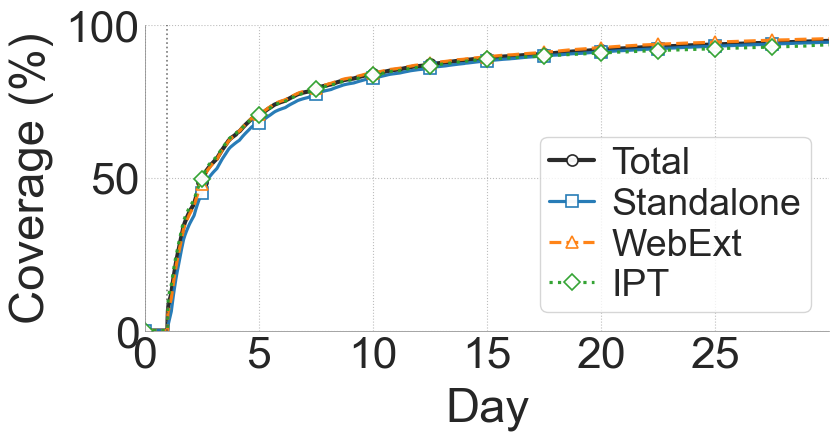

In [ ]:
figure = sva.plot_enumeration_baseline_proxy_overlay(inventory)
save_and_show(
        figure,
        group='enumeration coverage',
        factor='baseline proxy overlay',
        filename=f'enumeration-coverage-total.pdf',
    )

In [ ]:
for factor in ['Attacker Fraction', 'Churn Rate']:
    key = 'default' if factor == 'Baseline' else sva.normalize_name(factor)
    figure = sva.plot_factor_enumeration_total_only(inventory, factor)
    save_and_show(
        figure,
        group='enumeration coverage',
        factor=factor,
        filename=f'enumeration-coverage-{key}.pdf',
    )

TypeError: plot_enumeration_baseline_proxy_overlay() takes 1 positional argument but 2 were given

## 2. Unsuccessful-request rate

These blocking-mode plots show the percentage of client requests that were unsuccessful. Shading is mean ± one standard deviation across episodes.

/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  agg = agg.assign(episodes=len(timeseries_rows))
/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  agg = agg.assign(episodes=len(timeseries_rows))
/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling 

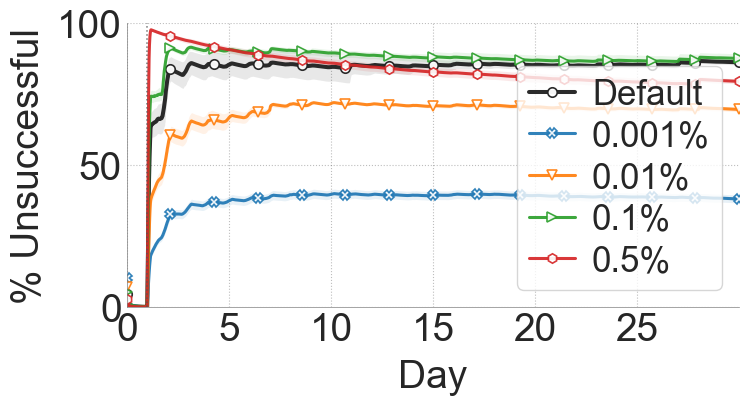

/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  agg = agg.assign(episodes=len(timeseries_rows))
/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  agg = agg.assign(episodes=len(timeseries_rows))
/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling 

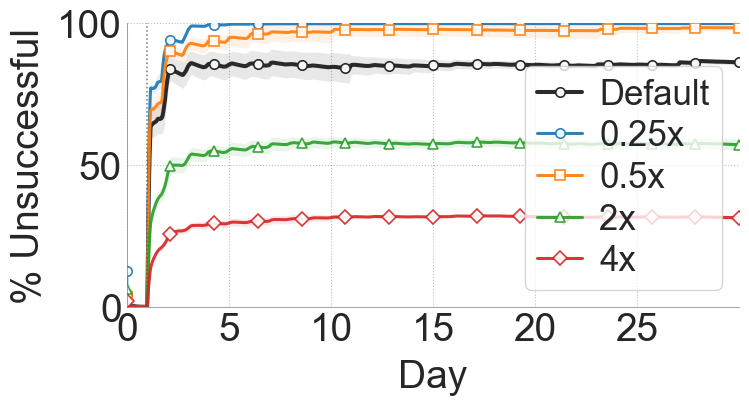

/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  agg = agg.assign(episodes=len(timeseries_rows))
/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  agg = agg.assign(episodes=len(timeseries_rows))
/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling 

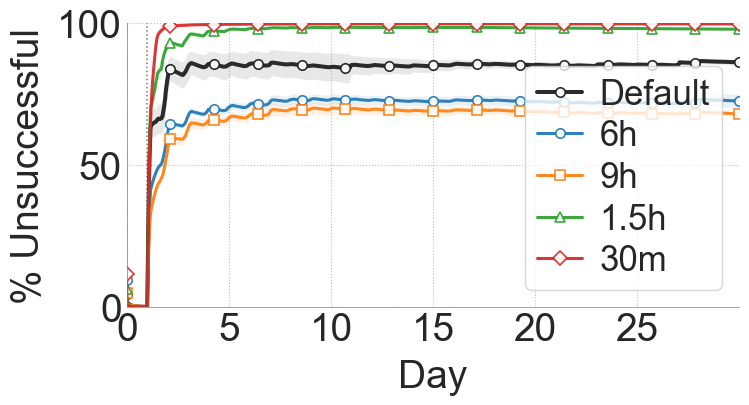

In [5]:
for factor in ['Attacker Fraction', 'Churn Rate', 'Connection Duration']:
    key = sva.normalize_name(factor)
    figure = sva.plot_factor_blocking_unsuccessful_request_rate_only(inventory, factor)
    save_and_show(
        figure,
        group='blocking unsuccessful rate',
        factor=factor,
        filename=f'blocking-unsuccessful-rate-{key}.pdf',
    )

## 3. Total client retries with percentile bands

The solid center curve is the daily median (50th percentile). The shaded regions cover the 25th–50th, 50th–75th, and 75th–99th percentiles; the 99th percentile is also drawn as a dashed boundary. The y-axis is logarithmic.

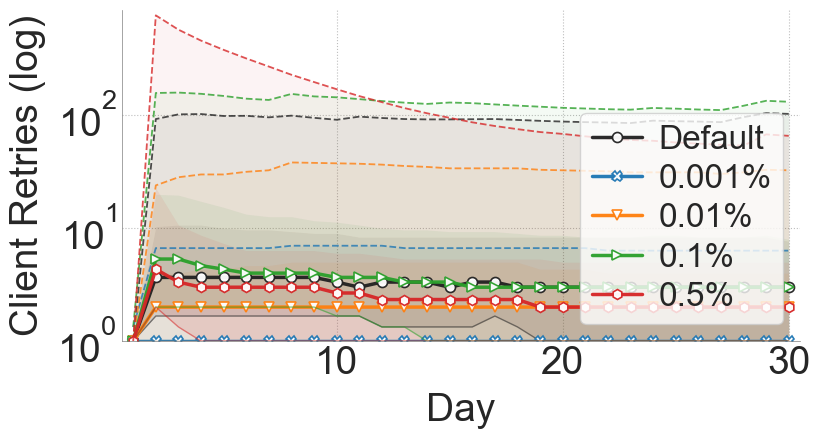

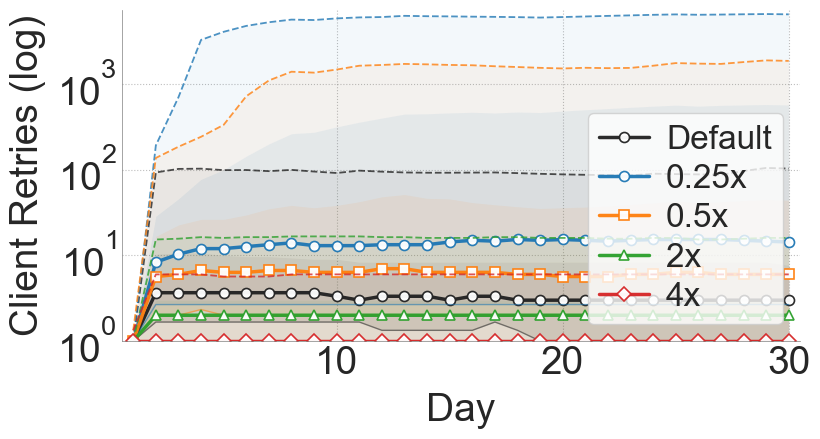

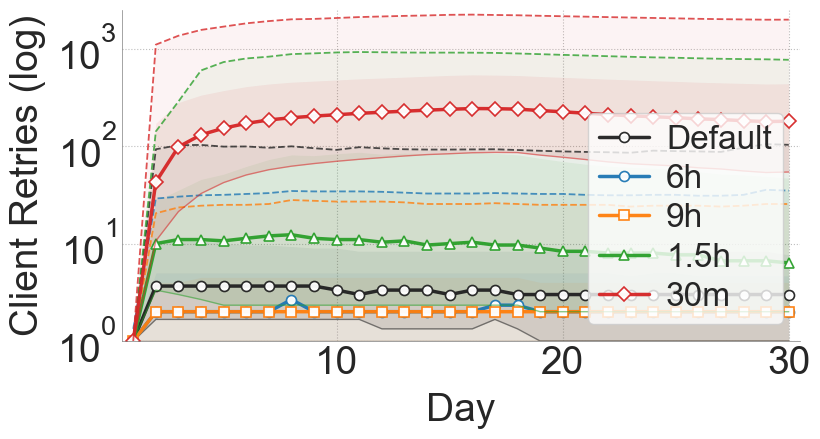

In [6]:
for factor in ['Attacker Fraction', 'Churn Rate', 'Connection Duration']:
    key = sva.normalize_name(factor)
    figure = sva.plot_blocking_retry_quantile_bands(
        inventory,
        factor,
        retry_prefix='total_retry_attempt',
        hours_per_bucket=24.0,
    )
    save_and_show(
        figure,
        group='blocking total retry percentile bands',
        factor=factor,
        filename=f'blocking-total-retry-percentile-bands-{key}.pdf',
    )

## 4. Standalone-proxy churn sensitivity

The 0.1× standalone-churn dataset contains only default-scenario runs, so this section makes like-for-like default comparisons among normal standalone churn, 0.1× churn, and 0.5× churn. Enumeration coverage shows standalone proxies only; the other two figures use the metrics above.

In [11]:
STANDALONE_HALF_ROOT = DATA_CONTAINER / 'data' / 'Simulation Results' / 'standalone_half_churn_rate'
STANDALONE_TENTH_ROOT = DATA_CONTAINER / 'data' / 'Simulation Results' / 'standalone_one_tenth_churn_rate'

for required_directory in [STANDALONE_HALF_ROOT, STANDALONE_TENTH_ROOT]:
    if not required_directory.is_dir():
        raise FileNotFoundError(f'Missing standalone-churn dataset: {required_directory}')

standalone_settings = [
    ('standalone_churn_0_1', 'Standalone 0.1× churn', STANDALONE_TENTH_ROOT, 'default/{mode}/episode-*/sim.log'),
    ('standalone_churn_0_5', 'Standalone 0.5× churn', STANDALONE_HALF_ROOT, 'default/{mode}/episode-*/sim.log'),
]
standalone_rows = []

for variant_order, (scenario_key, scenario_label, data_root, path_pattern) in enumerate(standalone_settings):
    sva.SCENARIO_METADATA[scenario_key] = {
        'factor': 'Standalone Churn',
        'label': scenario_label,
        'factor_order': len(sva.EXPERIMENT_GROUPS),
        'variant_order': variant_order,
    }
    sva.SHORT_SCENARIO_LABELS[scenario_key] = scenario_label.replace('Standalone ', '')

    for mode in sva.MODE_LABELS:
        for path in sorted(data_root.glob(path_pattern.format(mode=mode))):
            _, attackers = sva._read_header(f'file:{path}')
            standalone_rows.append({
                'locator': f'file:{path}',
                'source_type': 'filesystem',
                'display_path': str(path.relative_to(REPO_ROOT)),
                'scenario_raw': scenario_key,
                'scenario_key': scenario_key,
                'scenario_label': scenario_label,
                'mode': mode,
                'mode_label': sva.MODE_LABELS[mode],
                'episode': path.parent.name.lower(),
                'attackers': attackers,
                'factor': 'Standalone Churn',
                'factor_order': len(sva.EXPERIMENT_GROUPS),
                'variant_order': variant_order,
            })

standalone_variants = pd.DataFrame(standalone_rows)
if standalone_variants.empty:
    raise RuntimeError('No 0.1× or 0.5× standalone-churn logs were found.')

standalone_comparison_inventory = pd.concat(
    [inventory, standalone_variants],
    ignore_index=True,
)
display(
    standalone_variants
    .groupby(['mode_label', 'scenario_label'], as_index=False)
    .agg(episodes=('episode', 'nunique'))
)

,mode_label,scenario_label,episodes
0,Blocking,Standalone 0.1× churn,3
1,Blocking,Standalone 0.5× churn,3
2,Enumeration,Standalone 0.1× churn,3
3,Enumeration,Standalone 0.5× churn,3


/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  agg = agg.assign(episodes=len(timeseries_rows))
/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  agg = agg.assign(episodes=len(timeseries_rows))
/Users/pengchen/websocket-snowflake/notebooks/simulation_variation_analysis.py:1889: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling 

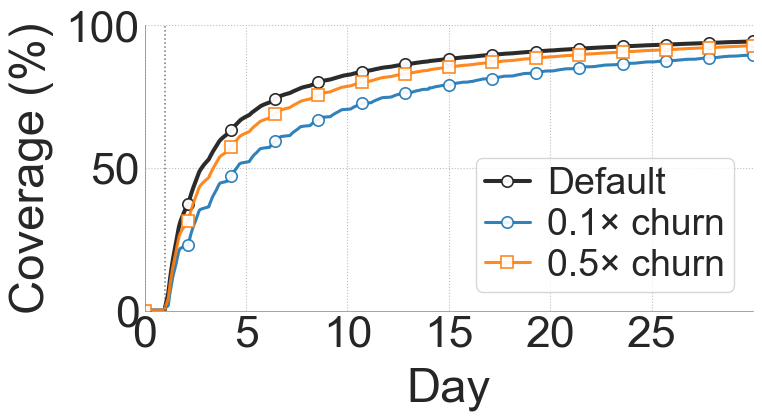

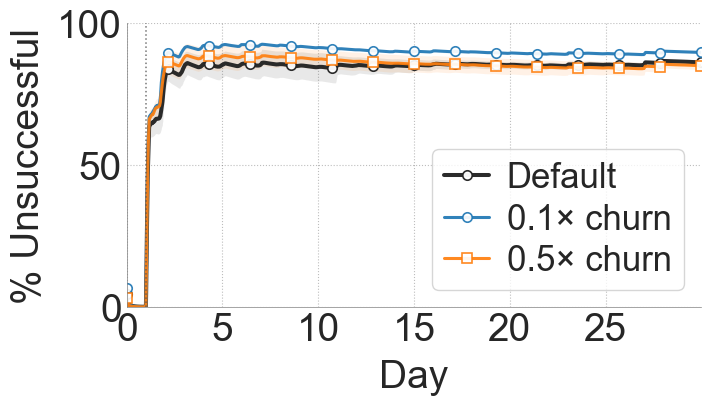

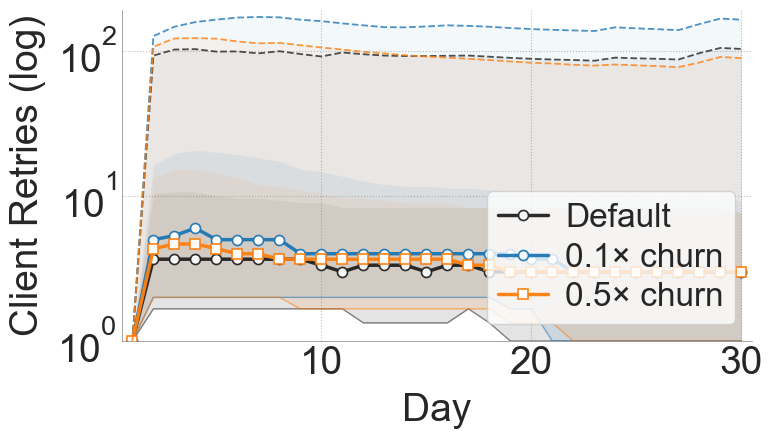

In [12]:
standalone_figure_specs = [
    (
        'enumeration coverage — standalone churn',
        sva.plot_factor_enumeration_coverage_only(
            standalone_comparison_inventory, 'Standalone Churn', proxy_type='standalone'
        ),
        'enumeration-coverage-standalone-churn.pdf',
    ),
    (
        'blocking unsuccessful rate — standalone churn',
        sva.plot_factor_blocking_unsuccessful_request_rate_only(
            standalone_comparison_inventory, 'Standalone Churn'
        ),
        'blocking-unsuccessful-rate-standalone-churn.pdf',
    ),
    (
        'blocking total retry percentile bands — standalone churn',
        sva.plot_blocking_retry_quantile_bands(
            standalone_comparison_inventory,
            'Standalone Churn',
            retry_prefix='total_retry_attempt',
            hours_per_bucket=24.0,
        ),
        'blocking-total-retry-percentile-bands-standalone-churn.pdf',
    ),
]

for group, figure, filename in standalone_figure_specs:
    save_and_show(
        figure,
        group=group,
        factor='Standalone Churn',
        filename=filename,
    )

## Exported figures

In [9]:
export_table = pd.DataFrame(exports)
display(export_table)
print(f'Generated {len(export_table)} figures in {OUTPUT_DIR}')

,group,factor,path
0,enumeration coverage,Baseline,/Users/pengchen/websocket-snowflake/notebooks/...
1,enumeration coverage,Attacker Fraction,/Users/pengchen/websocket-snowflake/notebooks/...
2,enumeration coverage,Churn Rate,/Users/pengchen/websocket-snowflake/notebooks/...
3,blocking unsuccessful rate,Attacker Fraction,/Users/pengchen/websocket-snowflake/notebooks/...
4,blocking unsuccessful rate,Churn Rate,/Users/pengchen/websocket-snowflake/notebooks/...
5,blocking unsuccessful rate,Connection Duration,/Users/pengchen/websocket-snowflake/notebooks/...
6,blocking total retry percentile bands,Attacker Fraction,/Users/pengchen/websocket-snowflake/notebooks/...
7,blocking total retry percentile bands,Churn Rate,/Users/pengchen/websocket-snowflake/notebooks/...
8,blocking total retry percentile bands,Connection Duration,/Users/pengchen/websocket-snowflake/notebooks/...
9,enumeration coverage — standalone churn,Standalone Churn,/Users/pengchen/websocket-snowflake/notebooks/...


Generated 12 figures in /Users/pengchen/websocket-snowflake/notebooks/figures/selected_simulation_figures
